# 2025 Eye Rating Leaderboard

Reads the pre-computed Eye Ratings from the database and resolves player names.

**Scale:** 100 = League Average | +10 = 1 Std Dev Better | -10 = 1 Std Dev Worse

In [1]:
import sys, os
sys.path.append(os.path.abspath('../'))

import pandas as pd
import sqlite3
from pybaseball import playerid_reverse_lookup
from src.db_manager import get_db_connection

In [2]:
# 1. Load Ratings from DB or Leaderboard CSV (season-filtered)
conn = get_db_connection()
cursor = conn.cursor()
cursor.execute("PRAGMA table_info(eye_ratings)")
cols = [col[1] for col in cursor.fetchall()]
lb = pd.DataFrame()
if 'season' in cols:
    lb = pd.read_sql_query('SELECT * FROM eye_ratings WHERE season = 2025 ORDER BY eye_rating DESC', conn)

if len(lb) == 0:
    cursor.execute("PRAGMA table_info(swing_ratings)")
    s_cols = [col[1] for col in cursor.fetchall()]
    if 'season' in s_cols:
        lb = pd.read_sql_query('SELECT * FROM swing_ratings WHERE season = 2025 ORDER BY swing_rating DESC', conn)
conn.close()

if len(lb) == 0:
    for csv_candidate in ['../data/leaderboards/2025_dva_leaderboard.csv', 'data/leaderboards/2025_dva_leaderboard.csv']:
        if os.path.exists(csv_candidate):
            lb = pd.read_csv(csv_candidate)
            break

if 'swing_rating' in lb.columns and 'eye_rating' not in lb.columns:
    lb['eye_rating'] = lb['swing_rating']

print(f"Loaded {len(lb)} batter ratings for 2025.")
lb.head()


Loaded 532 batter ratings.


,batter_id,season,n_pitches,ll_per_pitch,mean_sigma_x,mean_sigma_z,swing_rate,mean_p_strike,z_score,eye_rating,rank,updated_at
0,678391,2025,246,-1.041123,0.006740,0.007452,0.495935,0.466672,2.787327,127.9,1,2026-02-12 15:04:17.527818
1,663656,2025,2439,-1.063389,0.007924,0.008584,0.454695,0.425743,2.636886,126.4,2,2026-02-12 15:04:17.527818
2,608369,2025,1669,-1.100373,0.007884,0.008537,0.499101,0.394137,2.386994,123.9,3,2026-02-12 15:04:17.527818
3,663330,2025,613,-1.124578,0.010080,0.010306,0.446982,0.374433,2.223444,122.2,4,2026-02-12 15:04:17.527818
4,642136,2025,768,-1.133171,0.007147,0.007664,0.481771,0.424651,2.165385,121.7,5,2026-02-12 15:04:17.527818


In [3]:
# 2. Resolve Player Names
if 'player_name' not in lb.columns or lb['player_name'].isna().any() or (lb['player_name'] == 'Unknown').any():
    print("Looking up player names... (this may take a moment)")
    all_ids = lb['batter_id'].tolist()
    names_df = playerid_reverse_lookup(all_ids, key_type='mlbam')

    # Build name mapping
    names_df['full_name'] = names_df['name_first'].str.title() + ' ' + names_df['name_last'].str.title()
    name_map = dict(zip(names_df['key_mlbam'], names_df['full_name']))

    lb['player_name'] = lb['batter_id'].map(name_map)
    lb['player_name'] = lb['player_name'].fillna('Unknown')

print(f"Resolved {lb['player_name'].ne('Unknown').sum()} / {len(lb)} names.")


Looking up player names... (this may take a moment)
Gathering player lookup table. This may take a moment.
Resolved 532 / 532 names.


In [ ]:
# 3. TOP 10 — Eagle Eyes
if 'eye_sigma_ft' not in lb.columns:
    if 'mean_sigma_x' in lb.columns and 'mean_sigma_z' in lb.columns:
        lb['eye_sigma_ft'] = (lb['mean_sigma_x'] + lb['mean_sigma_z']) / 2.0
    else:
        lb['eye_sigma_ft'] = float('nan')

print('=== TOP 10 EAGLE EYES (2025) ===')
top = lb.head(10)[['rank', 'player_name', 'eye_rating', 'eye_sigma_ft', 'n_pitches', 'swing_rate']].copy()
top['swing_rate'] = (top['swing_rate'] * 100).round(1).astype(str) + '%'
top['eye_rating'] = top['eye_rating'].round(1)
top['eye_sigma_ft'] = top['eye_sigma_ft'].round(3)
display(top)


In [ ]:
# 4. BOTTOM 10 — The Gamblers
print('=== BOTTOM 10 GAMBLERS (2025) ===')
bot = lb.tail(10)[['rank', 'player_name', 'eye_rating', 'eye_sigma_ft', 'n_pitches', 'swing_rate']].copy()
bot['swing_rate'] = (bot['swing_rate'] * 100).round(1).astype(str) + '%'
bot['eye_rating'] = bot['eye_rating'].round(1)
bot['eye_sigma_ft'] = bot['eye_sigma_ft'].round(3)
display(bot)

=== BOTTOM 10 GAMBLERS (2025) ===


,rank,player_name,eye_rating,eye_sigma_ft,n_pitches,swing_rate
522,523,Jac Caglianone,77.9,0.619,858,51.3%
523,524,Christian Encarnacion-Strand,77.5,0.621,469,56.3%
524,525,Andrew Knizner,77.1,0.623,321,48.6%
525,526,Jhonkensy Noel,76.8,0.625,576,61.3%
526,527,Jason Heyward,76.5,0.626,347,46.4%
527,528,Oneil Cruz,74.1,0.638,2235,41.6%
528,529,Lenyn Sosa,71.3,0.653,2056,51.0%
529,530,Javier Báez,69.3,0.663,1644,55.7%
530,531,Jose Iglesias,68.4,0.667,1378,45.1%
531,532,Jonah Bride,68.0,0.669,556,33.3%


In [ ]:
# 5. Search for a specific player
def lookup(name):
    matches = lb[lb['player_name'].str.contains(name, case=False, na=False)]
    return matches[['rank', 'player_name', 'eye_rating', 'eye_sigma_ft', 'n_pitches', 'swing_rate']]

# Example: lookup('soto')
lookup('tucker')

,rank,player_name,eye_rating,eye_sigma_ft,n_pitches,swing_rate
2,3,Kyle Tucker,129.1,0.359739,2439,0.454695


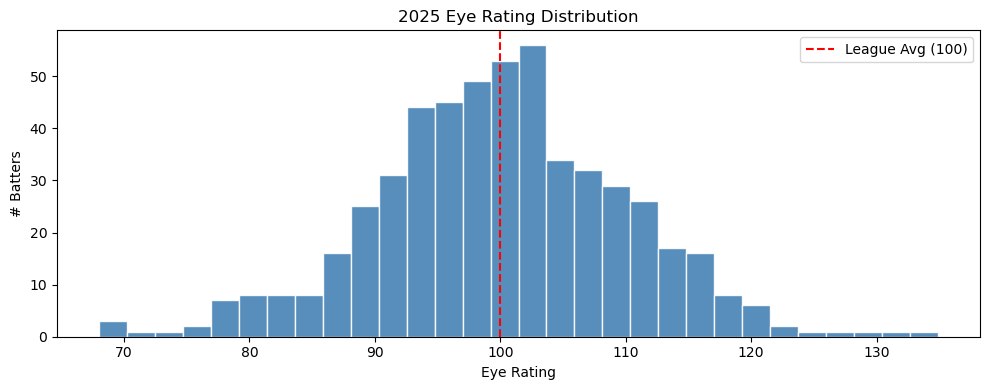

In [ ]:
# 6. Distribution Plot
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lb['eye_rating'], bins=30, color='steelblue', edgecolor='white', alpha=0.9)
ax.axvline(100, color='red', linestyle='--', label='League Avg (100)')
ax.set_xlabel('Eye Rating')
ax.set_ylabel('# Batters')
ax.set_title('2025 Eye Rating Distribution')
ax.legend()
plt.tight_layout()
plt.show()